Dataset created successfully!

First five records:
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Missing Values:
YearsExperience    0
Salary             0
dtype: int64

Total Records: 30


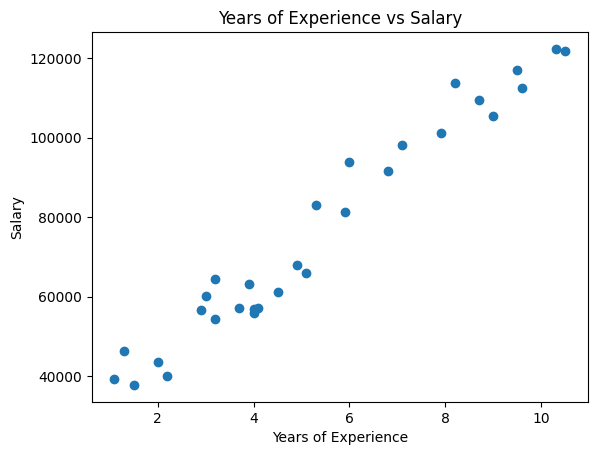


Training Records: 24
Testing Records: 6

Model trained successfully!

Actual Salaries:
[ 37731 122391  57081  63218 116969 109431]

Predicted Salaries:
[ 40748.96184072 122699.62295594  64961.65717022  63099.14214487
 115249.56285456 107799.50275317]

MODEL EVALUATION
Mean Absolute Error: 2446.17
Mean Squared Error: 12823412.3
Root Mean Squared Error: 3580.98
R2 Score: 0.9882


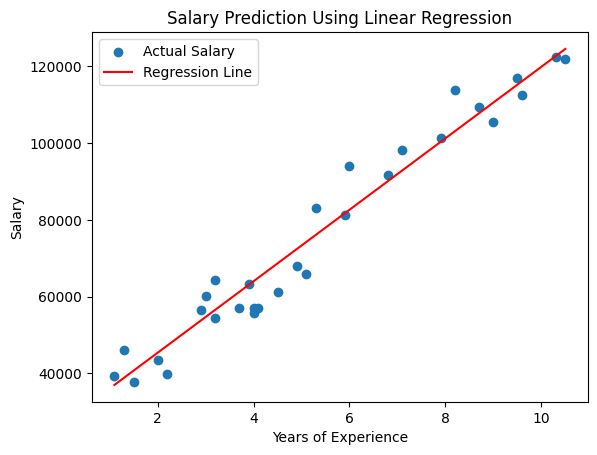


SALARY PREDICTION EQUATION
Slope: 9312.58
Intercept: 26780.1
Salary = 9312.58 * YearsExperience + 26780.10

Model saved successfully as SalaryPred.model
Saved model loaded successfully!

SALARY PREDICTION FOR A NEW EMPLOYEE


Enter years of experience:  5



Years of Experience: 5.0
Predicted Salary: Rs. 73342.97

Salary Prediction Project Completed Successfully!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
data = {
    'YearsExperience': [
        1.1, 1.3, 1.5, 2.0, 2.2,
        2.9, 3.0, 3.2, 3.2, 3.7,
        3.9, 4.0, 4.0, 4.1, 4.5,
        4.9, 5.1, 5.3, 5.9, 6.0,
        6.8, 7.1, 7.9, 8.2, 8.7,
        9.0, 9.5, 9.6, 10.3, 10.5
    ],
    'Salary': [
        39343, 46205, 37731, 43525, 39891,
        56642, 60150, 54445, 64445, 57189,
        63218, 55794, 56957, 57081, 61111,
        67938, 66029, 83088, 81363, 93940,
        91738, 98273, 101302, 113812, 109431,
        105582, 116969, 112635, 122391, 121872
    ]
}

df = pd.DataFrame(data)
df.to_csv("Salary_data.csv", index=False)
print("Dataset created successfully!")
print("\nFirst five records:")
print(df.head())
print("\nMissing Values:")
print(df.isnull().sum())
df = df.dropna()
print("\nTotal Records:", len(df))
plt.scatter(df['YearsExperience'], df['Salary'])
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Years of Experience vs Salary")
plt.show()
X = df[['YearsExperience']]
y = df['Salary']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)
print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))
model = LinearRegression()
model.fit(X_train, y_train)
print("\nModel trained successfully!")
y_pred = model.predict(X_test)
print("\nActual Salaries:")
print(y_test.values)
print("\nPredicted Salaries:")
print(y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("\nMODEL EVALUATION")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
plt.scatter(
    df['YearsExperience'],
    df['Salary'],
    label="Actual Salary"
)
plt.plot(
    df['YearsExperience'],
    model.predict(df[['YearsExperience']]),
    color='red',
    label="Regression Line"
)
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction Using Linear Regression")
plt.legend()
plt.show()
print("\nSALARY PREDICTION EQUATION")
print("Slope:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))
print(
    f"Salary = {model.coef_[0]:.2f} * YearsExperience "
    f"+ {model.intercept_:.2f}"
)
with open("SalaryPred.model", "wb") as file:
    pickle.dump(model, file)
print("\nModel saved successfully as SalaryPred.model")
with open("SalaryPred.model", "rb") as file:
    loaded_model = pickle.load(file)
print("Saved model loaded successfully!")
print("\nSALARY PREDICTION FOR A NEW EMPLOYEE")
experience = float(input("Enter years of experience: "))
new_data = pd.DataFrame({
    'YearsExperience': [experience]
})
predicted_salary = loaded_model.predict(new_data)
print("\nYears of Experience:", experience)
print("Predicted Salary: Rs.", round(predicted_salary[0], 2))
print("\nSalary Prediction Project Completed Successfully!")

